# Telco Customer Churn: optimización, Explainable AI y decisión de negocio

**Asignatura:** Aprendizaje Automático
**Estudiante:** Ismael Adrian Paredes Rosero
**Dataset:** Telco Customer Churn

### Pregunta de negocio
¿Qué clientes presentan mayor riesgo de abandono, qué características pesan más en la predicción y qué acciones de retención podrían evaluarse a partir de los resultados?

### Reglas metodológicas
- El conjunto de **test queda aislado** hasta la evaluación final.
- Todo el preprocesamiento vive en un `ColumnTransformer` dentro de un `Pipeline`.
- Todos los modelos y optimizadores usan las mismas particiones y el mismo protocolo.
- Ningún modelo se elige solo por Accuracy.
- La importancia predictiva de una variable **no demuestra causalidad**.

### Estructura
1. Auditoría y preparación
2. Train/Test y pipeline
3. Modelado y comparación
4. Optimización de hiperparámetros
5. Optimización multiobjetivo
6. Cierre de la selección y evaluación final
7. Características relevantes
8. Ranking de clientes por riesgo
9. Explainable AI: SHAP y LIME
10. Propuesta de negocio
11. Exportación y checklist

In [1]:
import json
import pickle
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from catboost import CatBoostClassifier
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import randint, spearmanr
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path.cwd()))
from src.churn_common import (ARTIFACTS, CATEGORICAL, FEATURES, ID_COL, LABELS, NUMERIC,
                              RANDOM_STATE, TARGET, build_preprocessor, calibrate, clean,
                              group_by_original, lime_category_maps, lime_decode,
                              lime_encode, lime_label, original_feature, to_logit)

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID_COLOR = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID_COLOR, "axes.labelcolor": MUTED, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.grid": True,
    "axes.axisbelow": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

# Las búsquedas se guardan en disco porque la latencia cambia un poco en cada corrida
# y eso puede alterar el frente de Pareto. Con False, el notebook reproduce las cifras
# citadas en el texto; con True, repite todas las búsquedas desde cero.
FORCE_RERUN_SEARCH = False
SEARCH_DIR = ARTIFACTS / "search"
SEARCH_DIR.mkdir(parents=True, exist_ok=True)

## 1. Auditoría y preparación
Se revisan dimensiones, tipos, faltantes, inconsistencias, la distribución de `Churn` y el problema de `TotalCharges`.

In [2]:
raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dimensiones:", raw.shape)
print("Filas duplicadas:", raw.duplicated().sum())
print("customerID únicos:", raw[ID_COL].nunique())
print("Faltantes explícitos:", raw.isna().sum().sum())
raw.head()

Dimensiones: (7043, 21)
Filas duplicadas: 0
customerID únicos: 7043
Faltantes explícitos: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [3]:
audit = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "valores_distintos": raw.nunique(),
    "ejemplos": [raw[c].unique()[:4].tolist() for c in raw.columns],
})
audit

,tipo,valores_distintos,ejemplos
customerID,str,7043,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,str,2,"[Female, Male]"
SeniorCitizen,int64,2,"[0, 1]"
Partner,str,2,"[Yes, No]"
Dependents,str,2,"[No, Yes]"
tenure,int64,73,"[1, 34, 2, 45]"
PhoneService,str,2,"[No, Yes]"
MultipleLines,str,3,"[No phone service, No, Yes]"
InternetService,str,3,"[DSL, Fiber optic, No]"
OnlineSecurity,str,3,"[No, Yes, No internet service]"


In [4]:
# TotalCharges llega como texto: se buscan los valores que no son números.
as_number = pd.to_numeric(raw["TotalCharges"], errors="coerce")
blank = raw[as_number.isna()]
print("Valores no numéricos:", len(blank), "| contenido:", blank["TotalCharges"].unique())
print("Antigüedad de esos clientes:", blank["tenure"].unique())
print("Clientes con tenure = 0 en todo el dataset:", (raw["tenure"] == 0).sum())
blank[[ID_COL, "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]].head()

Valores no numéricos: 11 | contenido: <ArrowStringArray>
[' ']
Length: 1, dtype: str
Antigüedad de esos clientes: [0]
Clientes con tenure = 0 en todo el dataset: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.5500,,Two year,No
753,3115-CZMZD,0,20.2500,,Two year,No
936,5709-LVOEQ,0,80.8500,,Two year,No
1082,4367-NUYAO,0,25.7500,,Two year,No
1340,1371-DWPAZ,0,56.0500,,Two year,No


In [5]:
df = clean(raw)
y_all = (df[TARGET] == "Yes").astype(int)

# Inconsistencia a comprobar: "No internet service" debe coincidir con InternetService = No.
dependent = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
             "StreamingTV", "StreamingMovies"]
no_internet = df["InternetService"] == "No"
consistent = all(((df[c] == "No internet service") == no_internet).all() for c in dependent)
print("Servicios de internet coherentes con InternetService:", consistent)
print("MultipleLines coherente con PhoneService:",
      ((df["MultipleLines"] == "No phone service") == (df["PhoneService"] == "No")).all())

gap = (df["TotalCharges"] - df["tenure"] * df["MonthlyCharges"]).abs()
print("Diferencia mediana entre TotalCharges y tenure*MonthlyCharges:", round(gap.median(), 2))
print()
print(df[TARGET].value_counts(normalize=True).round(4))
df[NUMERIC].describe().T

Servicios de internet coherentes con InternetService: True
MultipleLines coherente con PhoneService: True
Diferencia mediana entre TotalCharges y tenure*MonthlyCharges: 28.65

Churn
No    0.7346
Yes   0.2654
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
tenure,"7,043.0000",32.3711,24.5595,0.0000,9.0000,29.0000,55.0000,72.0000
MonthlyCharges,"7,043.0000",64.7617,30.0900,18.2500,35.5000,70.3500,89.8500,118.7500
TotalCharges,"7,032.0000","2,283.3004","2,266.7714",18.8000,401.4500,"1,397.4750","3,794.7375","8,684.8000"


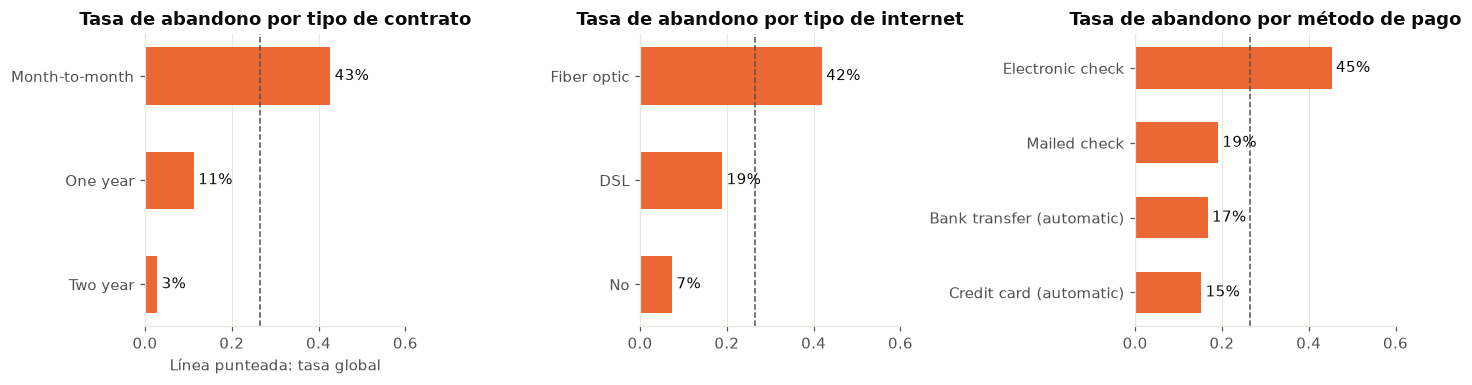

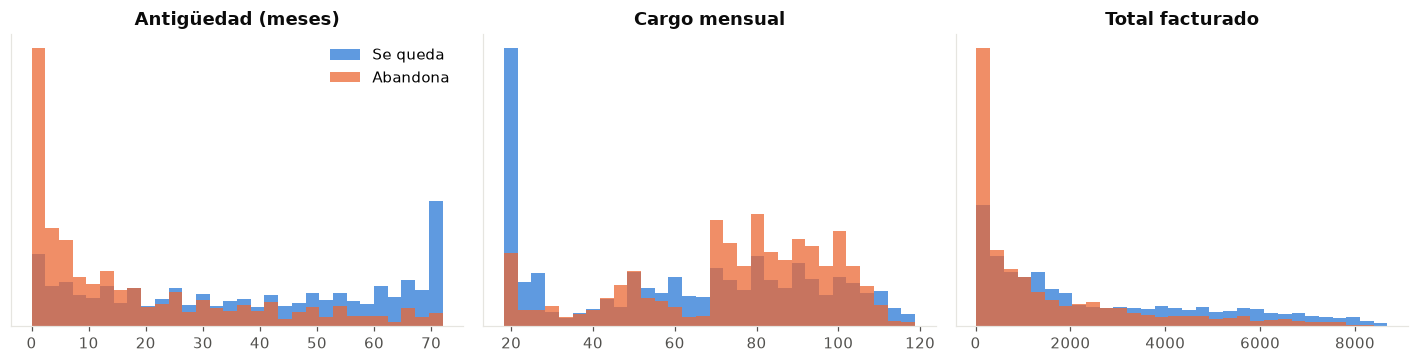

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)[TARGET].apply(lambda s: (s == "Yes").mean()).sort_values()
    ax.barh(rate.index, rate.values, color=ORANGE, height=0.55)
    ax.axvline(y_all.mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(f"Tasa de abandono por {LABELS[col].lower()}")
    ax.set_xlim(0, 0.6)
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(rate.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", color=INK)
axes[0].set_xlabel("Línea punteada: tasa global")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, col in zip(axes, NUMERIC):
    bins = np.histogram_bin_edges(df[col].dropna(), bins=30)
    ax.hist(df.loc[y_all == 0, col].dropna(), bins=bins, color=BLUE, alpha=0.75, label="Se queda", density=True)
    ax.hist(df.loc[y_all == 1, col].dropna(), bins=bins, color=ORANGE, alpha=0.75, label="Abandona", density=True)
    ax.set_title(LABELS[col])
    ax.set_yticks([])
    ax.grid(False)
axes[0].legend()
plt.tight_layout()
plt.show()

### Hallazgos que afectan decisiones posteriores

1. **`TotalCharges` es texto y tiene 11 valores en blanco.** Los 11 corresponden a los únicos clientes con `tenure = 0`, ninguno de los cuales abandonó. No son datos perdidos al azar: son clientes que aún no han recibido factura. Por eso se convierten a número y se imputan con 0, en lugar de eliminarlos o usar la mediana.
2. **Las clases están desbalanceadas:** 26.5 % de abandono. Un modelo que siempre responde "no abandona" ya acierta 73.5 %, así que Accuracy no sirve como métrica principal.
3. **El tipo de contrato separa mucho:** 43 % de abandono en mes a mes, 11 % en un año y 3 % en dos años. También destacan fibra óptica (42 %) y pago con cheque electrónico (45 %).
4. **El abandono se concentra al inicio:** la antigüedad mediana es de 10 meses entre quienes se van y 38 entre quienes se quedan. Esto apunta a que los primeros meses son críticos.
5. **Hay información redundante.** Las seis columnas de servicios repiten "No internet service" de forma coherente con `InternetService`, y `TotalCharges` es casi `tenure × MonthlyCharges` (diferencia mediana de 28.65). Las importancias se repartirán entre variables relacionadas, lo que hay que recordar al interpretarlas.

## 2. Train/Test y pipeline
`customerID` identifica a cada cliente y es único en todas las filas, de modo que no aporta patrón alguno: si entrara al modelo solo serviría para memorizar. Se excluye de los predictores, pero se conserva aparte para construir el ranking.

In [7]:
X = df[FEATURES]
X_train, X_test, y_train, y_test = train_test_split(
    X, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)

assert set(X_train.index).isdisjoint(X_test.index)
print("Train:", X_train.shape, "| tasa de abandono:", round(y_train.mean(), 4))
print("Test: ", X_test.shape, "| tasa de abandono:", round(y_test.mean(), 4))

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
N_JOBS = 5  # un proceso por fold, igual para todos los optimizadores


def make_pipeline(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


make_pipeline(LogisticRegression())

Train: (5634, 19) | tasa de abandono: 0.2654
Test:  (1409, 19) | tasa de abandono: 0.2654


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

**¿Cómo evita este procedimiento el data leakage?**

1. La partición se hace antes de cualquier cálculo que aprenda de los datos. `clean()` solo convierte tipos fila a fila.
2. El escalado y la codificación están dentro del `Pipeline`, así que en cada fold se ajustan únicamente con la parte de entrenamiento de ese fold.
3. `TotalCharges` vacío se imputa con la constante 0 porque esos clientes tienen `tenure = 0` y aún no han sido facturados. Una constante no usa estadísticas de otras filas.
4. Modelos, hiperparámetros, umbral y calibración se deciden solo con `X_train`. `X_test` se usa por primera vez en la sección 6.

## 3. Modelado y comparación
Se comparan seis clasificadores con los mismos cinco folds. `DummyClassifier` sirve de línea base: muestra qué se obtiene sin aprender nada.

Las matrices de confusión usan predicciones *out-of-fold*: cada cliente de train se predice con un modelo que no lo vio.

In [8]:
def logreg():
    return LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)


def forest():
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=RANDOM_STATE, n_jobs=1)


def catboost():
    return CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05, verbose=0,
                              auto_class_weights="Balanced", random_seed=RANDOM_STATE,
                              thread_count=1, allow_writing_files=False)


base_estimators = [("lr", logreg()), ("rf", forest()), ("cat", catboost())]
candidates = {
    "Dummy (línea base)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": logreg(),
    "Random Forest": forest(),
    "CatBoost": catboost(),
    "Voting (soft)": VotingClassifier(base_estimators, voting="soft"),
    "Stacking": StackingClassifier(base_estimators, cv=3,
                                   final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced")),
}

rows, oof_confusions = [], {}
for name, model in candidates.items():
    pipe = make_pipeline(model)
    start = time.perf_counter()
    res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=N_JOBS)
    row = {"modelo": name}
    row.update({m: res[f"test_{m}"].mean() for m in SCORING})
    row["f1_std"] = res["test_f1"].std()
    row["tiempo_s"] = time.perf_counter() - start
    rows.append(row)
    oof = cross_val_predict(pipe, X_train, y_train, cv=CV, n_jobs=N_JOBS)
    oof_confusions[name] = confusion_matrix(y_train, oof)

model_comparison = pd.DataFrame(rows).set_index("modelo")
model_comparison.sort_values("f1", ascending=False)

,accuracy,precision,recall,f1,roc_auc,f1_std,tiempo_s
modelo,,,,,,,
CatBoost,0.7714,0.5492,0.7726,0.6418,0.8440,0.0154,2.7821
Voting (soft),0.7723,0.5520,0.7518,0.6365,0.8450,0.0244,5.5354
Stacking,0.7586,0.5304,0.7920,0.6352,0.8473,0.0188,18.7039
Logistic Regression,0.7485,0.5169,0.8013,0.6282,0.8460,0.0231,0.2332
Random Forest,0.7783,0.5723,0.6508,0.6089,0.8228,0.0236,2.7620
Dummy (línea base),0.7346,0.0000,0.0000,0.0000,0.5000,0.0000,5.0284


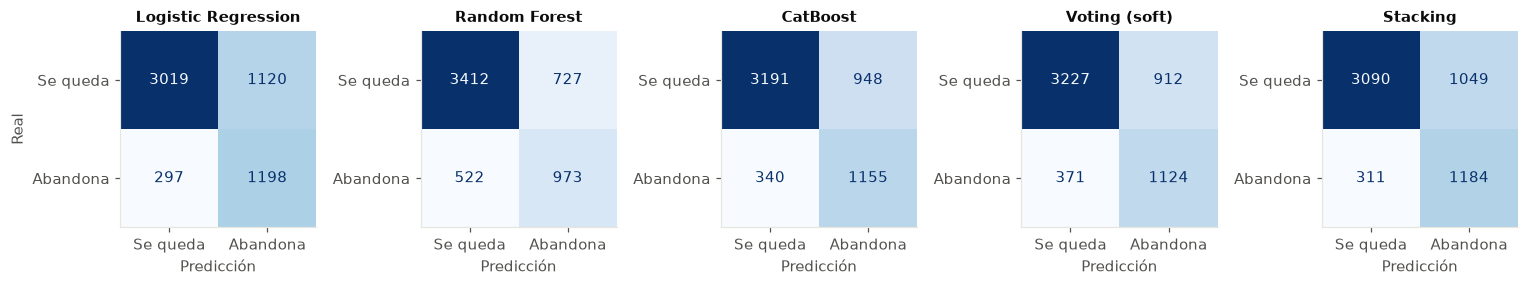

Abandonos reales en train: 1495


,falsos_negativos,pct_abandonos_no_detectados
Logistic Regression,297,0.1987
Random Forest,522,0.3492
CatBoost,340,0.2274
Voting (soft),371,0.2482
Stacking,311,0.2080


In [9]:
show = [n for n in candidates if not n.startswith("Dummy")]
fig, axes = plt.subplots(1, len(show), figsize=(14, 2.9))
for ax, name in zip(axes, show):
    ConfusionMatrixDisplay(oof_confusions[name], display_labels=["Se queda", "Abandona"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real" if ax is axes[0] else "")
    ax.grid(False)
plt.tight_layout()
plt.show()

fn = pd.Series({n: oof_confusions[n][1, 0] for n in show}, name="falsos_negativos")
print("Abandonos reales en train:", int(y_train.sum()))
fn.to_frame().assign(pct_abandonos_no_detectados=lambda d: d["falsos_negativos"] / y_train.sum())

### Interpretación

**Métricas más relevantes.** Accuracy engaña aquí: el Dummy logra 0.735 sin detectar a nadie. Importan más:
- **Recall:** qué parte de los abandonos se detecta.
- **F1:** equilibrio entre detectar abandonos y no gastar ofertas de más. Es la métrica principal de la optimización.
- **ROC-AUC:** calidad del orden de riesgo, clave cuando el presupuesto solo alcanza para una parte de la cartera.

**Falsos negativos.** Son clientes que se van sin que nadie actúe, y suelen costar más que un falso positivo, que solo gasta una oferta. Random Forest con parámetros por defecto deja escapar 522 de 1495 abandonos (34.9 %), mientras que Logistic Regression deja 297 (19.9 %).

**Modelo inicial.** Con estos resultados se elegiría **CatBoost**: tiene el mayor F1 (0.642) con un recall de 0.773. Logistic Regression es una alternativa muy sólida: logra el mayor recall (0.801) y un ROC-AUC de 0.846 con un coste mínimo. Stacking obtiene el mayor ROC-AUC (0.847) pero no compensa su complejidad. Las diferencias entre los cuatro mejores son pequeñas frente a su variación entre folds (0.015 a 0.024).

**Por qué se optimiza Random Forest.** No es el mejor sin ajustar; de hecho, es el peor de los modelos reales en F1 (0.609). Se elige como base del experimento porque tiene más margen de mejora, sus hiperparámetros cambian de verdad el coste de inferencia, permite SHAP exacto y el enunciado pide comparar su Feature Importance.

El tiempo del Dummy incluye el arranque de los procesos en paralelo, por eso no refleja su coste real.

## 4. Optimización de hiperparámetros

**Modelo base:** Random Forest con `class_weight="balanced"` fijo, el mismo preprocesamiento y los mismos folds.

**Métrica principal, definida antes de observar test:** F1 de la clase de abandono.

**Presupuesto común:** 54 configuraciones por estrategia, cada una evaluada con validación cruzada de 5 folds, y un máximo de 5 procesos en paralelo.

### Cómo funciona cada estrategia

| Estrategia | Funcionamiento |
|---|---|
| **Grid Search** | Evalúa todas las combinaciones de una rejilla fija. Es exhaustivo dentro de la rejilla, pero solo explora los valores listados. |
| **Random Search** | Toma combinaciones al azar del espacio. Con igual presupuesto prueba más valores distintos de cada hiperparámetro que una rejilla. |
| **TPE (Optuna)** | Optimización bayesiana. Separa los ensayos en buenos y malos, modela la densidad de cada grupo y propone donde la razón buenos/malos es mayor. Aprende de los ensayos anteriores. |
| **NSGA-II (Optuna)** | Algoritmo genético multiobjetivo. Mantiene una población, ordena por dominancia de Pareto y distancia de agrupamiento, y cruza y muta las mejores soluciones. Devuelve un frente de compromisos en lugar de un único ganador. |

### Hiperparámetros y espacios de búsqueda

| Hiperparámetro | Qué controla | Grid (54 combinaciones) | Random / TPE / NSGA-II |
|---|---|---|---|
| `n_estimators` | Número de árboles | 100, 300, 500 | entero 50–600 |
| `max_depth` | Profundidad máxima | 6, 10, 16 | entero 3–24 |
| `min_samples_leaf` | Mínimo de clientes por hoja | 1, 5, 20 | entero 1–40 |
| `max_features` | Variables evaluadas por división | sqrt, 0.5 | sqrt, log2, 0.3, 0.5, 0.8 |

In [10]:
BUDGET = 54
NSGA_POPULATION = 18
NSGA_TOTAL = 126   # 7 generaciones; las primeras 54 evaluaciones se comparan en esta sección
MAX_FEATURES = ["sqrt", "log2", 0.3, 0.5, 0.8]


def rf_pipeline(params=None):
    model = RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE,
                                   n_jobs=1, **(params or {}))
    return make_pipeline(model)


def cached(name, compute):
    path = SEARCH_DIR / f"{name}.joblib"
    if path.exists() and not FORCE_RERUN_SEARCH:
        return joblib.load(path)
    result = compute()
    joblib.dump(result, path)
    return result


def from_sklearn(name, search, elapsed):
    cv = pd.DataFrame(search.cv_results_)
    best = search.best_index_
    return {
        "estrategia": name,
        "configuraciones": len(cv),
        "tiempo_s": elapsed,
        "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "metricas": {m: float(cv.loc[best, f"mean_test_{m}"]) for m in SCORING},
        "f1_por_ensayo": cv["mean_test_f1"].to_numpy(),
    }


def run_grid():
    grid = {"model__n_estimators": [100, 300, 500], "model__max_depth": [6, 10, 16],
            "model__min_samples_leaf": [1, 5, 20], "model__max_features": ["sqrt", 0.5]}
    search = GridSearchCV(rf_pipeline(), grid, cv=CV, scoring=SCORING, refit="f1", n_jobs=N_JOBS)
    return from_sklearn("Grid Search", *timed_fit(search))


def run_random():
    space = {"model__n_estimators": randint(50, 601), "model__max_depth": randint(3, 25),
             "model__min_samples_leaf": randint(1, 41), "model__max_features": MAX_FEATURES}
    search = RandomizedSearchCV(rf_pipeline(), space, n_iter=BUDGET, cv=CV, scoring=SCORING,
                                refit="f1", n_jobs=N_JOBS, random_state=RANDOM_STATE)
    return from_sklearn("Random Search", *timed_fit(search))


def timed_fit(search):
    start = time.perf_counter()
    search.fit(X_train, y_train)
    return search, time.perf_counter() - start


def suggest(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 600),
        "max_depth": trial.suggest_int("max_depth", 3, 24),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 40),
        "max_features": trial.suggest_categorical("max_features", MAX_FEATURES),
    }


def cv_metrics(params, keep_estimators=False):
    res = cross_validate(rf_pipeline(params), X_train, y_train, cv=CV, scoring=SCORING,
                         n_jobs=N_JOBS, return_estimator=keep_estimators)
    return {m: float(res[f"test_{m}"].mean()) for m in SCORING}, res


def run_tpe():
    def objective(trial):
        metrics, _ = cv_metrics(suggest(trial))
        trial.set_user_attr("metricas", metrics)
        return metrics["f1"]

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    start = time.perf_counter()
    study.optimize(objective, n_trials=BUDGET)
    elapsed = time.perf_counter() - start
    return {
        "estrategia": "TPE (Optuna)",
        "configuraciones": len(study.trials),
        "tiempo_s": elapsed,
        "best_params": study.best_params,
        "metricas": study.best_trial.user_attrs["metricas"],
        "f1_por_ensayo": np.array([t.value for t in study.trials]),
    }

### Objetivo del algoritmo multiobjetivo
NSGA-II optimiza dos objetivos a la vez, que se formalizan en la sección 5. La latencia se mide sobre 1000 clientes de `X_train`, con un solo proceso y como mediana de siete repeticiones, porque en un solo intento el ruido del sistema pesaría demasiado.

In [11]:
LATENCY_SAMPLE = X_train.iloc[:1000]


def latency_ms(pipeline, repeats=7):
    pipeline.predict_proba(LATENCY_SAMPLE)  # calentamiento
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        pipeline.predict_proba(LATENCY_SAMPLE)
        times.append(time.perf_counter() - start)
    return float(np.median(times) * 1000)


def run_nsga2():
    def objective(trial):
        start = time.perf_counter()
        metrics, res = cv_metrics(suggest(trial), keep_estimators=True)
        fitted = res["estimator"][0]
        latency = latency_ms(fitted)
        trial.set_user_attr("metricas", metrics)
        trial.set_user_attr("size_mb", len(pickle.dumps(fitted)) / 1e6)
        trial.set_user_attr("elapsed", time.perf_counter() - start)
        return metrics["f1"], latency

    sampler = optuna.samplers.NSGAIISampler(population_size=NSGA_POPULATION, seed=RANDOM_STATE)
    study = optuna.create_study(directions=["maximize", "minimize"], sampler=sampler)
    study.optimize(objective, n_trials=NSGA_TOTAL)

    rows = []
    for t in study.trials:
        row = {"ensayo": t.number, "f1": t.values[0], "latencia_ms": t.values[1], **t.params,
               "size_mb": t.user_attrs["size_mb"], "elapsed_s": t.user_attrs["elapsed"]}
        row.update({m: t.user_attrs["metricas"][m] for m in SCORING if m != "f1"})
        rows.append(row)
    return pd.DataFrame(rows)


grid_result = cached("grid", run_grid)
random_result = cached("random", run_random)
tpe_result = cached("tpe", run_tpe)
nsga_trials = cached("nsga2", run_nsga2)

first = nsga_trials.iloc[:BUDGET]
nsga_best = first.loc[first["f1"].idxmax()]
PARAM_NAMES = ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]


def native(value):
    return value.item() if hasattr(value, "item") else value


nsga_result = {
    "estrategia": "NSGA-II (Optuna)",
    "configuraciones": BUDGET,
    "tiempo_s": float(first["elapsed_s"].sum()),
    "best_params": {k: native(nsga_best[k]) for k in PARAM_NAMES},
    "metricas": {m: float(nsga_best[m]) for m in SCORING},
    "f1_por_ensayo": first["f1"].to_numpy(),
}
results = [grid_result, random_result, tpe_result, nsga_result]

optimizers = pd.DataFrame([{
    "estrategia": r["estrategia"], "configuraciones": r["configuraciones"],
    "tiempo_s": r["tiempo_s"], "s_por_config": r["tiempo_s"] / r["configuraciones"],
    **r["metricas"], **r["best_params"],
} for r in results]).set_index("estrategia")
optimizers

,configuraciones,tiempo_s,s_por_config,accuracy,precision,recall,f1,roc_auc,max_depth,max_features,min_samples_leaf,n_estimators
estrategia,,,,,,,,,,,,
Grid Search,54,153.4820,2.8423,0.7648,0.5402,0.7672,0.6339,0.8440,16,sqrt,5,100
Random Search,54,167.5563,3.1029,0.7602,0.5329,0.7866,0.6352,0.8455,9,log2,3,162
TPE (Optuna),54,87.8266,1.6264,0.7591,0.5313,0.7946,0.6367,0.8471,16,log2,15,169
NSGA-II (Optuna),54,186.1627,3.4475,0.7570,0.5282,0.7980,0.6355,0.8475,15,log2,18,217


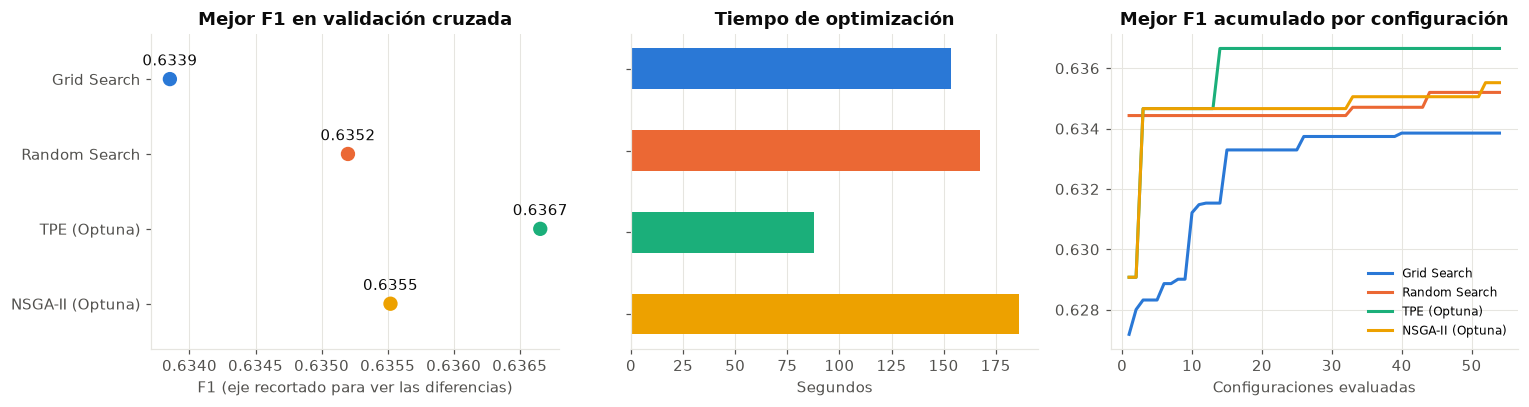

In [12]:
colors = [BLUE, ORANGE, AQUA, YELLOW]
names = [r["estrategia"] for r in results]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

ax = axes[0]
ax.scatter([r["metricas"]["f1"] for r in results], names, color=colors, s=70, zorder=3)
ax.set_title("Mejor F1 en validación cruzada")
ax.set_xlabel("F1 (eje recortado para ver las diferencias)")
ax.margins(y=0.2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for r in results:
    ax.annotate(f"{r['metricas']['f1']:.4f}", (r["metricas"]["f1"], r["estrategia"]),
                textcoords="offset points", xytext=(0, 9), ha="center", color=INK)

ax = axes[1]
ax.barh(names, [r["tiempo_s"] for r in results], color=colors, height=0.5)
ax.set_title("Tiempo de optimización")
ax.set_xlabel("Segundos")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_yticklabels([])

ax = axes[2]
for r, color in zip(results, colors):
    ax.plot(range(1, len(r["f1_por_ensayo"]) + 1), np.maximum.accumulate(r["f1_por_ensayo"]),
            color=color, linewidth=2, label=r["estrategia"])
ax.set_title("Mejor F1 acumulado por configuración")
ax.set_xlabel("Configuraciones evaluadas")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Análisis de las estrategias

**La mejora importante no viene del optimizador, sino de ajustar el modelo.** Las cuatro estrategias suben el F1 de 0.609 (Random Forest por defecto) a entre 0.634 y 0.637. Lo que consiguen es regularizar el bosque, con hojas más grandes y profundidad limitada, para reducir el sobreajuste.

**Entre estrategias, las diferencias no son concluyentes.** La distancia entre la mejor y la peor es de 0.0028, muy por debajo de la variación entre folds, que ronda 0.014 a 0.017. Además, cada estrategia se ejecutó con una sola semilla.

| Estrategia | F1 | Tiempo | Ventajas | Limitaciones |
|---|---|---|---|---|
| Grid Search | 0.6339 | 153 s | Simple, exhaustivo y fácil de auditar | Solo prueba valores listados; crece de forma exponencial con cada hiperparámetro |
| Random Search | 0.6352 | 168 s | Simple y explora más valores por hiperparámetro | No aprende de los ensayos anteriores; depende del azar |
| TPE (Optuna) | **0.6367** | **88 s** | Se concentra en zonas prometedoras; alcanzó su mejor valor cerca de la configuración 14 | Más difícil de explicar; evalúa de forma secuencial |
| NSGA-II (Optuna) | 0.6355 | 186 s | Entrega un conjunto de compromisos | Más lento: además mide latencia y tamaño, y necesita muchas evaluaciones |

Sobre los tiempos: dependen sobre todo del tamaño de los bosques que cada estrategia decide probar, así que no miden solo la eficiencia del algoritmo. Grid y Random además reparten configuraciones y folds entre los procesos, mientras que Optuna solo reparte los folds.

**Estrategia elegida.** Para un solo objetivo, **TPE**: con el mismo presupuesto obtuvo el mejor F1 en el menor tiempo, aunque esa ventaja en F1 no es estadísticamente demostrable. Para este proyecto se usa **NSGA-II** en la selección final porque también importa el coste de inferencia.

## 5. Optimización multiobjetivo

### Formulación
Sea $\theta$ una configuración de hiperparámetros dentro del espacio $\Theta$ de la sección 4:

$$\max_{\theta \in \Theta} \; f_1(\theta) = \frac{1}{5}\sum_{k=1}^{5} F1_k(\theta)$$

$$\min_{\theta \in \Theta} \; f_2(\theta) = \operatorname{mediana}_{r=1..7} \; L_r(\theta)$$

donde $F1_k$ es el F1 de la clase de abandono en el fold $k$ y $L_r$ es el tiempo, en milisegundos, de puntuar 1000 clientes con el pipeline completo.

Una configuración $\theta_a$ **domina** a $\theta_b$ si no es peor en ningún objetivo y es estrictamente mejor en al menos uno. Las soluciones no dominadas forman el frente de Pareto.

### Por qué estos objetivos
El producto es un SaaS que atiende a varios ISP desde la misma infraestructura. F1 representa la calidad de la lista de clientes a retener. La latencia representa el coste de puntuar carteras completas y la rapidez de respuesta cuando un agente consulta a un cliente en línea. Mejorar uno suele empeorar el otro, porque más árboles y más profundos cuestan más tiempo.

In [13]:
def pareto_mask(frame):
    f1, lat = frame["f1"].to_numpy(), frame["latencia_ms"].to_numpy()
    keep = np.ones(len(frame), dtype=bool)
    for i in range(len(frame)):
        dominated_by = (f1 >= f1[i]) & (lat <= lat[i]) & ((f1 > f1[i]) | (lat < lat[i]))
        keep[i] = not dominated_by.any()
    return keep


trials = nsga_trials.copy()
trials["no_dominada"] = pareto_mask(trials)
front = trials[trials["no_dominada"]].sort_values("latencia_ms").reset_index(drop=True)

# Punto de rodilla: la solución más cercana al ideal con ambos objetivos en escala 0-1.
norm_f1 = (front["f1"].max() - front["f1"]) / (front["f1"].max() - front["f1"].min())
norm_lat = (front["latencia_ms"] - front["latencia_ms"].min()) / (front["latencia_ms"].max() - front["latencia_ms"].min())
front["distancia_ideal"] = np.sqrt(norm_f1 ** 2 + norm_lat ** 2)
knee = front.loc[front["distancia_ideal"].idxmin()]
fastest, strongest = front.iloc[0], front.iloc[-1]

print(f"Ensayos: {len(trials)} | soluciones no dominadas: {len(front)}")
front[["ensayo", "f1", "latencia_ms", "size_mb", "recall", "precision", *PARAM_NAMES, "distancia_ideal"]]

Ensayos: 126 | soluciones no dominadas: 4


,ensayo,f1,latencia_ms,size_mb,recall,precision,n_estimators,max_depth,min_samples_leaf,max_features,distancia_ideal
0,112,0.6325,19.6782,0.6112,0.7946,0.5255,53,7,18,0.3000,1.0000
1,72,0.6346,20.2987,0.6080,0.7906,0.5301,53,14,29,0.5000,0.3153
2,32,0.6351,26.3742,1.1712,0.7987,0.5273,98,7,14,0.3000,0.3152
3,51,0.6355,43.9504,3.0831,0.7980,0.5282,217,15,18,log2,1.0000


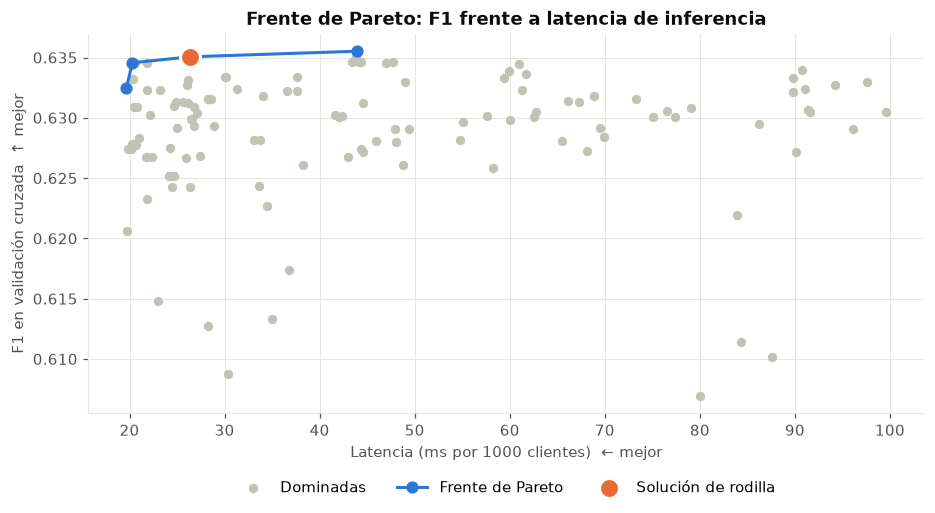

,f1,recall,precision,roc_auc,latencia_ms,size_mb,n_estimators,max_depth,min_samples_leaf,max_features
Más rápida,0.6325,0.7946,0.5255,0.8483,19.6782,0.6112,53,7,18,0.3000
Rodilla,0.6351,0.7987,0.5273,0.8482,26.3742,1.1712,98,7,14,0.3000
Mayor F1,0.6355,0.7980,0.5282,0.8475,43.9504,3.0831,217,15,18,log2


In [14]:
fig, ax = plt.subplots(figsize=(8.6, 4.8))
others = trials[~trials["no_dominada"]]
ax.scatter(others["latencia_ms"], others["f1"], s=26, color="#c3c2b7", label="Dominadas")
ax.plot(front["latencia_ms"], front["f1"], color=BLUE, linewidth=2, marker="o", markersize=7,
        label="Frente de Pareto")
ax.scatter([knee["latencia_ms"]], [knee["f1"]], s=170, color=ORANGE, edgecolor="white",
           linewidth=2, zorder=5, label="Solución de rodilla")
ax.set_xlabel("Latencia (ms por 1000 clientes)  ← mejor")
ax.set_ylabel("F1 en validación cruzada  ↑ mejor")
ax.set_title("Frente de Pareto: F1 frente a latencia de inferencia")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
plt.tight_layout()
plt.show()

compare_front = pd.DataFrame([fastest, knee, strongest], index=["Más rápida", "Rodilla", "Mayor F1"])
compare_front[["f1", "recall", "precision", "roc_auc", "latencia_ms", "size_mb", *PARAM_NAMES]]

### Comprobación: ¿las diferencias de F1 son reales?
Antes de cerrar la selección se comparan, con los mismos folds y solo en train, la solución de rodilla, la mejor configuración de TPE y CatBoost sin ajustar. La diferencia por fold es pareada: como los folds son los mismos, muestra si un modelo gana de forma consistente o solo por azar.

In [15]:
def compare_finalists():
    finalists = {"RF rodilla (NSGA-II)": rf_pipeline({k: native(knee[k]) for k in PARAM_NAMES}),
                 "RF mejor TPE": rf_pipeline(tpe_result["best_params"]),
                 "CatBoost sin ajustar": make_pipeline(catboost())}
    rows, folds = [], {}
    for name, pipe in finalists.items():
        res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=N_JOBS,
                             return_estimator=True)
        folds[name] = res["test_f1"]
        rows.append({"modelo": name, "f1": res["test_f1"].mean(), "f1_std": res["test_f1"].std(),
                     "recall": res["test_recall"].mean(), "precision": res["test_precision"].mean(),
                     "roc_auc": res["test_roc_auc"].mean(), "latencia_ms": latency_ms(res["estimator"][0]),
                     "size_mb": len(pickle.dumps(res["estimator"][0])) / 1e6})
    return pd.DataFrame(rows).set_index("modelo"), pd.DataFrame(folds)


finalists_table, finalists_folds = cached("finalists", compare_finalists)
paired = finalists_folds.sub(finalists_folds["RF rodilla (NSGA-II)"], axis=0).drop(columns="RF rodilla (NSGA-II)")
print("Diferencia de F1 por fold frente a la rodilla:")
print(paired.round(4).to_string())
print("Media:", paired.mean().round(4).to_dict())
finalists_table

Diferencia de F1 por fold frente a la rodilla:
   RF mejor TPE  CatBoost sin ajustar
0        0.0069                0.0012
1        0.0012                0.0021
2       -0.0083                0.0151
3        0.0010                0.0075
4        0.0072                0.0080
Media: {'RF mejor TPE': 0.0016, 'CatBoost sin ajustar': 0.0068}


,f1,f1_std,recall,precision,roc_auc,latencia_ms,size_mb
modelo,,,,,,,
RF rodilla (NSGA-II),0.6351,0.0140,0.7987,0.5273,0.8482,26.0640,1.1709
RF mejor TPE,0.6367,0.0173,0.7946,0.5313,0.8471,36.6770,2.8336
CatBoost sin ajustar,0.6418,0.0154,0.7726,0.5492,0.8440,14.1422,0.3443


### Análisis del frente de Pareto

**Compromiso observado.** NSGA-II evaluó 126 configuraciones y dejó 4 soluciones no dominadas. Pasar de la más rápida a la de mayor F1 multiplica la latencia por 2.2 (de 19.7 a 44.0 ms) y gana solo 0.003 de F1. El frente es casi plano en calidad: la velocidad se puede mejorar mucho sin perder casi nada.

| Solución | F1 | Recall | Latencia | Tamaño | Lectura de negocio |
|---|---|---|---|---|---|
| Más rápida (53 árboles) | 0.6325 | 0.795 | 19.7 ms | 0.6 MB | Conviene si el volumen de consultas fuese muy alto |
| **Rodilla (98 árboles)** | **0.6351** | **0.799** | **26.4 ms** | **1.2 MB** | Mantiene la calidad con un coste bajo |
| Mayor F1 (217 árboles) | 0.6355 | 0.798 | 44.0 ms | 3.1 MB | Paga 67 % más de latencia por 0.0004 de F1 |

**Solución seleccionada: ensayo 32**, con 98 árboles, profundidad 7, mínimo 14 clientes por hoja y `max_features = 0.3`. Frente a la de mayor F1, reduce la latencia 40 % y el tamaño 62 % a cambio de una diferencia de F1 que es ruido.

La regla de la rodilla no la separa con claridad del ensayo 72 (53 árboles): sus distancias al ideal son 0.3152 y 0.3153, un empate práctico. El desempate es de negocio: el ensayo 32 tiene mayor recall (0.799 frente a 0.791) y solo cuesta 6 ms más.

**Por qué una solución puede convenir más que otra.** Depende del uso. Una campaña mensual por lotes puede tolerar la solución más lenta. Un agente que consulta en línea y un SaaS que atiende a varios ISP valoran la velocidad y el coste. Hay que mantener la proporción: a 26 ms por 1000 clientes, una cartera de 50 000 se puntúa en alrededor de 1.3 s, por lo que a esta escala la latencia no es un cuello de botella. La ventaja real de un modelo pequeño es ser más barato de servir y dar explicaciones LIME más rápidas, porque LIME hace miles de predicciones por cliente.

### Limitaciones que deben quedar claras

**El frente es una aproximación.** La mejor configuración de TPE (F1 0.6367, 36.7 ms) domina al extremo de mayor F1 del frente. NSGA-II encontró su mejor F1 en el ensayo 51 y no lo superó en los 74 ensayos siguientes; lo que mejoró después fue la latencia. Una población de 18 durante 7 generaciones es poco para converger.

**El frente solo cubre Random Forest.** La comprobación anterior muestra que **CatBoost sin ajustar supera a la solución elegida en ambos objetivos**: F1 de 0.6418 frente a 0.6351, ganando en los 5 folds por 0.0068 en promedio, y latencia de 14.1 ms frente a 26.1 ms.

**Por qué se mantiene Random Forest.** La decisión no se apoya en que sea el mejor en F1, porque no lo es:
- El producto ordena clientes para un presupuesto limitado, y en la métrica de orden el Random Forest queda por delante: ROC-AUC de 0.8482 frente a 0.8440. Esta ventaja también es pequeña y no está demostrada.
- Detecta más abandonos con el umbral de 0.5: recall de 0.799 frente a 0.773.
- Permite comparar directamente con Feature Importance, como pide el enunciado.

**El siguiente experimento** sería optimizar CatBoost con el mismo protocolo. No se hizo aquí porque cambiaría el modelo base acordado para comparar las estrategias.

## 6. Cierre de la selección y evaluación final
Todo lo que sigue hasta la evaluación usa solo train:

1. Se fija el modelo final.
2. Se elige el umbral de decisión con predicciones out-of-fold.
3. Se calibran las probabilidades. `class_weight="balanced"` hace que el modelo trate a la clase minoritaria como si fuera tan frecuente como la mayoritaria, lo que infla las probabilidades. Sirve para ordenar clientes, pero el negocio necesita probabilidades realistas para estimar ingreso en riesgo. Se aplica calibración de Platt: una regresión logística sobre el logit de la salida del bosque.

Configuración seleccionada: {'n_estimators': 98, 'max_depth': 7, 'min_samples_leaf': 14, 'max_features': 0.3}


Umbral sobre la salida del bosque: 0.59 (F1 OOF 0.6352)
Umbral equivalente en probabilidad calibrada: 0.358
Probabilidad media sin calibrar: 0.407 | calibrada: 0.265 | tasa real: 0.265
Brier sin calibrar: 0.1604 | calibrado: 0.1342
           f1  recall  precision   marcados
umbral                                     
0.4500 0.6236  0.8294     0.4996 2,482.0000
0.5000 0.6349  0.7987     0.5269 2,266.0000
0.5500 0.6300  0.7478     0.5443 2,054.0000
0.5900 0.6352  0.7077     0.5763 1,836.0000
0.6500 0.6252  0.6314     0.6190 1,525.0000


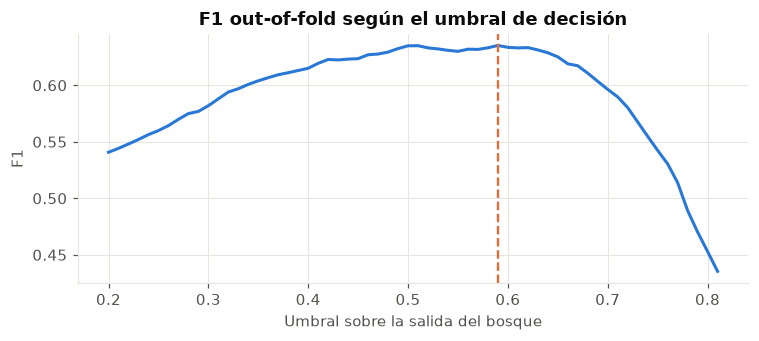

In [16]:
selected_params = {k: native(knee[k]) for k in PARAM_NAMES}
print("Configuración seleccionada:", selected_params)

final_pipe = rf_pipeline(selected_params)
oof_raw = cross_val_predict(final_pipe, X_train, y_train, cv=CV, method="predict_proba",
                            n_jobs=N_JOBS)[:, 1]

thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
f1_by_threshold = [f1_score(y_train, oof_raw >= t) for t in thresholds]
threshold_raw = float(thresholds[int(np.argmax(f1_by_threshold))])

calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(to_logit(oof_raw), y_train)
oof_cal = calibrate(calibrator, oof_raw)
threshold_cal = float(calibrate(calibrator, [threshold_raw])[0])

print(f"Umbral sobre la salida del bosque: {threshold_raw:.2f} (F1 OOF {max(f1_by_threshold):.4f})")
print(f"Umbral equivalente en probabilidad calibrada: {threshold_cal:.3f}")
print(f"Probabilidad media sin calibrar: {oof_raw.mean():.3f} | calibrada: {oof_cal.mean():.3f} | tasa real: {y_train.mean():.3f}")
print(f"Brier sin calibrar: {brier_score_loss(y_train, oof_raw):.4f} | calibrado: {brier_score_loss(y_train, oof_cal):.4f}")

cv_final = {
    "accuracy": accuracy_score(y_train, oof_raw >= threshold_raw),
    "precision": precision_score(y_train, oof_raw >= threshold_raw),
    "recall": recall_score(y_train, oof_raw >= threshold_raw),
    "f1": f1_score(y_train, oof_raw >= threshold_raw),
    "roc_auc": roc_auc_score(y_train, oof_raw),
}

threshold_check = pd.DataFrame({
    t: {"f1": f1_score(y_train, oof_raw >= t), "recall": recall_score(y_train, oof_raw >= t),
        "precision": precision_score(y_train, oof_raw >= t), "marcados": int((oof_raw >= t).sum())}
    for t in [0.45, 0.50, 0.55, threshold_raw, 0.65]}).T.rename_axis("umbral")
print(threshold_check.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(thresholds, f1_by_threshold, color=BLUE, linewidth=2)
ax.axvline(threshold_raw, color=ORANGE, linestyle="--", linewidth=1.5)
ax.set_title("F1 out-of-fold según el umbral de decisión")
ax.set_xlabel("Umbral sobre la salida del bosque")
ax.set_ylabel("F1")
plt.tight_layout()
plt.show()

### Evaluación final
Selección, umbral y calibración ya quedaron fijados. Esta es la **única** celda de evaluación sobre `X_test`: nada de lo que se observe aquí cambia esas decisiones.

              precision    recall  f1-score   support

    Se queda      0.884     0.803     0.842      1035
    Abandona      0.565     0.709     0.629       374

    accuracy                          0.778      1409
   macro avg      0.725     0.756     0.735      1409
weighted avg      0.799     0.778     0.785      1409

Probabilidad calibrada media: 0.267 | tasa real en test: 0.265
Brier calibrado en test: 0.1354


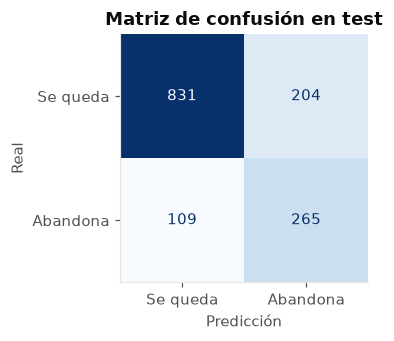

,CV (out-of-fold),Test,diferencia
accuracy,0.7843,0.7779,-0.0065
precision,0.5763,0.5650,-0.0112
recall,0.7077,0.7086,0.0009
f1,0.6352,0.6287,-0.0065
roc_auc,0.8474,0.8462,-0.0012


In [17]:
final_pipe.fit(X_train, y_train)

test_raw = final_pipe.predict_proba(X_test)[:, 1]
test_cal = calibrate(calibrator, test_raw)
test_pred = (test_raw >= threshold_raw).astype(int)

print(classification_report(y_test, test_pred, target_names=["Se queda", "Abandona"], digits=3))
test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
    "roc_auc": roc_auc_score(y_test, test_raw),
}
test_confusion = confusion_matrix(y_test, test_pred)
print(f"Probabilidad calibrada media: {test_cal.mean():.3f} | tasa real en test: {y_test.mean():.3f}")
print(f"Brier calibrado en test: {brier_score_loss(y_test, test_cal):.4f}")

fig, ax = plt.subplots(figsize=(3.8, 3.2))
ConfusionMatrixDisplay(test_confusion, display_labels=["Se queda", "Abandona"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Matriz de confusión en test")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.grid(False)
plt.tight_layout()
plt.show()

pd.DataFrame({"CV (out-of-fold)": cv_final, "Test": test_metrics}).assign(
    diferencia=lambda d: d["Test"] - d["CV (out-of-fold)"])

### Interpretación de la evaluación final

**El modelo generaliza bien.** Las métricas de test quedan a menos de 0.012 de las de validación: F1 0.629, recall 0.709, precision 0.565 y ROC-AUC 0.846. No hay señales de sobreajuste ni de fuga de información.

**Qué significa la matriz de confusión.** De 374 abandonos reales, el modelo detecta 265 y deja escapar 109 (29 %). También marca a 204 clientes que se quedarían. Es decir, cerca de 4 de cada 10 clientes marcados no iban a irse, y eso debe entrar en el coste de cualquier campaña.

**La calibración funcionó.** La probabilidad media estimada (26.7 %) casi coincide con la tasa real en test (26.5 %), y el error Brier en test (0.135) es similar al de train (0.134).

**Nota crítica sobre el umbral.** El umbral 0.59 se eligió maximizando F1, pero la curva es casi plana y con ruido. La tabla de la sección anterior muestra que frente a 0.50 gana solo 0.0003 de F1 a cambio de perder 9.1 puntos de recall (0.799 a 0.708) y ganar 4.9 de precision. Como un falso negativo suele costar más que un falso positivo, 0.50 habría sido más razonable.

Esa tabla se añadió después de la primera evaluación en test, así que el umbral **no se cambió**: hacerlo ahora invalidaría la regla de evaluar una sola vez. Las reejecuciones del notebook no alteraron ninguna decisión y las cifras de test son idénticas. El impacto práctico es limitado, porque el producto decide por ranking y presupuesto, no por este umbral.

## 7. Características relevantes
Se usan dos medidas clásicas:

- **`feature_importances_` (Random Forest):** cuánto reduce la impureza una variable en las divisiones del bosque, promediado entre árboles y calculado con datos de entrenamiento. Tiende a favorecer variables continuas o con muchos valores.
- **`permutation_importance`:** cuánto cae el ROC-AUC en test al barajar una variable. Es agnóstica al modelo y trabaja sobre las variables originales. Con variables correlacionadas puede subestimar: barajar una deja a la otra cubriendo su información.

Las columnas One-Hot tienen la forma `cat__Contract_Month-to-month`, que significa "el cliente tiene contrato mes a mes". Para ver el peso total de una variable se suman todas sus columnas.

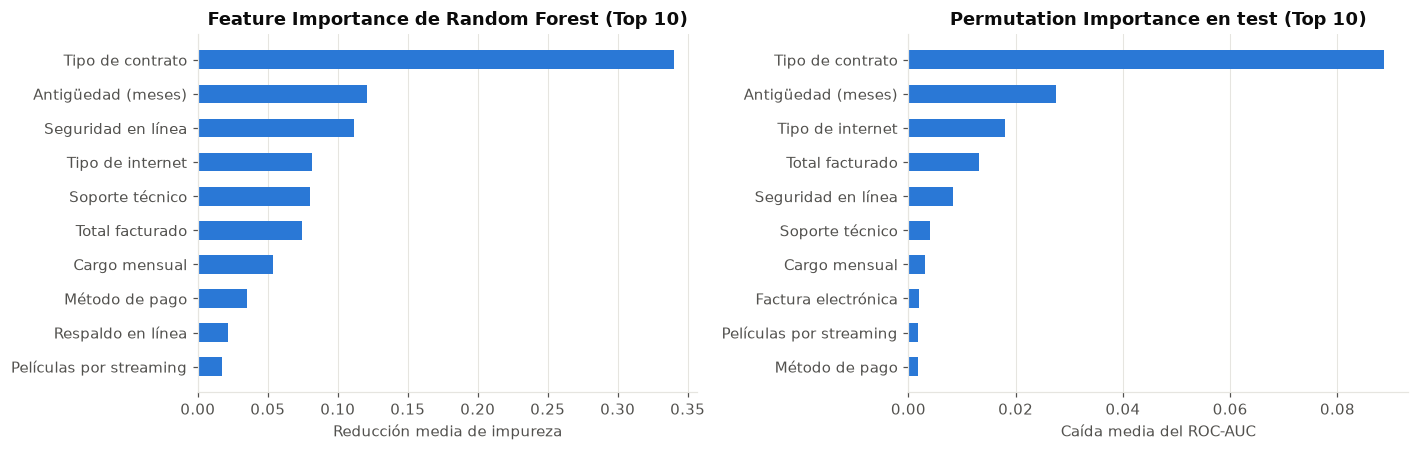

Top 10 columnas transformadas:


,importancia
cat__Contract_Month-to-month,0.2257
num__tenure,0.1211
cat__OnlineSecurity_No,0.0998
cat__Contract_Two year,0.0928
num__TotalCharges,0.0747
cat__TechSupport_No,0.0693
cat__InternetService_Fiber optic,0.0601
num__MonthlyCharges,0.0540
cat__PaymentMethod_Electronic check,0.0275
cat__Contract_One year,0.0214


In [18]:
prep = final_pipe.named_steps["prep"]
rf_model = final_pipe.named_steps["model"]
transformed_names = prep.get_feature_names_out()

rf_detail = pd.Series(rf_model.feature_importances_, index=transformed_names).sort_values(ascending=False)
rf_grouped = group_by_original(rf_model.feature_importances_, transformed_names).sort_values(ascending=False)

perm = permutation_importance(final_pipe, X_test, y_test, scoring="roc_auc", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=N_JOBS)
perm_series = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, series, title, xlabel in [
    (axes[0], rf_grouped.head(10), "Feature Importance de Random Forest (Top 10)", "Reducción media de impureza"),
    (axes[1], perm_series.head(10), "Permutation Importance en test (Top 10)", "Caída media del ROC-AUC"),
]:
    ax.barh([LABELS[i] for i in series.index], series.values, color=BLUE, height=0.55)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("Top 10 columnas transformadas:")
rf_detail.head(10).to_frame("importancia")

### Interpretación

**Variables más importantes.** Ambas medidas coinciden en el Top 2: tipo de contrato y antigüedad. Completan el grupo principal seguridad en línea, tipo de internet y soporte técnico.

**Columnas One-Hot.** `cat__Contract_Month-to-month` (0.226) es la columna con mayor peso, y `cat__Contract_Two year` (0.093) también pesa mucho aunque indica lo contrario: bajo riesgo. Estas medidas dicen cuánto se usa una variable, **no en qué dirección empuja**. El sentido lo aportará SHAP.

**Diferencias entre medidas.** `TotalCharges` sube a la cuarta posición en permutación y queda sexta en Random Forest. Como depende de antigüedad y cargo mensual, su importancia se reparte entre las tres y debe leerse con cautela.

**Importancia predictiva no implica causalidad.** Que el contrato mes a mes prediga abandono no significa que lo provoque. Puede que quien piensa irse evite comprometerse, de modo que obligar a firmar un contrato anual no cambiaría su decisión. Del mismo modo, la fibra óptica puede ser un indicador de precio, de competencia en esa zona o de calidad del servicio; los datos no permiten distinguirlo. Para saber si una acción funciona hace falta un experimento con grupo de control.

## 8. Ranking de clientes por riesgo
**Escenario:** el área comercial solo puede intervenir sobre el **10 % de los clientes del conjunto de evaluación con mayor riesgo estimado**.

In [19]:
scored = X_test.copy()
scored.insert(0, ID_COL, df.loc[X_test.index, ID_COL])
scored["churn_real"] = y_test
scored["p_raw"] = test_raw
scored["p_churn"] = test_cal
ranking = scored.sort_values("p_churn", ascending=False).reset_index(drop=True)

k = int(np.ceil(0.10 * len(ranking)))
top = ranking.head(k)
precision_at_k = top["churn_real"].mean()
capture = top["churn_real"].sum() / ranking["churn_real"].sum()
lift = precision_at_k / ranking["churn_real"].mean()

print(f"Clientes intervenidos: {k} de {len(ranking)}")
print(f"Abandonan de verdad: {int(top['churn_real'].sum())} ({precision_at_k:.1%})")
print(f"Elegidos al azar abandonarían: {ranking['churn_real'].mean():.1%}")
print(f"Lift: {lift:.2f}x | abandonos capturados: {capture:.1%}")

deciles = ranking.assign(decil=(np.arange(len(ranking)) * 10 // len(ranking)) + 1)
decile_table = deciles.groupby("decil").agg(
    clientes=("churn_real", "size"), abandonos=("churn_real", "sum"),
    tasa_real=("churn_real", "mean"), prob_media=("p_churn", "mean"))
decile_table["captura_acumulada"] = decile_table["abandonos"].cumsum() / decile_table["abandonos"].sum()

top[[ID_COL, "p_churn", "churn_real", "Contract", "tenure", "MonthlyCharges"]].head(10)

Clientes intervenidos: 141 de 1409
Abandonan de verdad: 107 (75.9%)
Elegidos al azar abandonarían: 26.5%
Lift: 2.86x | abandonos capturados: 28.6%


,customerID,p_churn,churn_real,Contract,tenure,MonthlyCharges
0,5178-LMXOP,0.8969,1,Month-to-month,1,95.1000
1,0295-PPHDO,0.8924,1,Month-to-month,1,95.4500
2,1069-XAIEM,0.8868,1,Month-to-month,1,85.0500
3,9248-OJYKK,0.8803,1,Month-to-month,1,76.4500
4,2609-IAICY,0.8706,1,Month-to-month,1,77.1500
5,4415-IJZTP,0.8593,1,Month-to-month,1,74.5000
6,2254-DLXRI,0.8475,0,Month-to-month,1,79.1500
7,6857-VWJDT,0.8468,1,Month-to-month,1,95.6500
8,2514-GINMM,0.8418,1,Month-to-month,1,79.5000
9,8375-DKEBR,0.8414,1,Month-to-month,1,69.6000


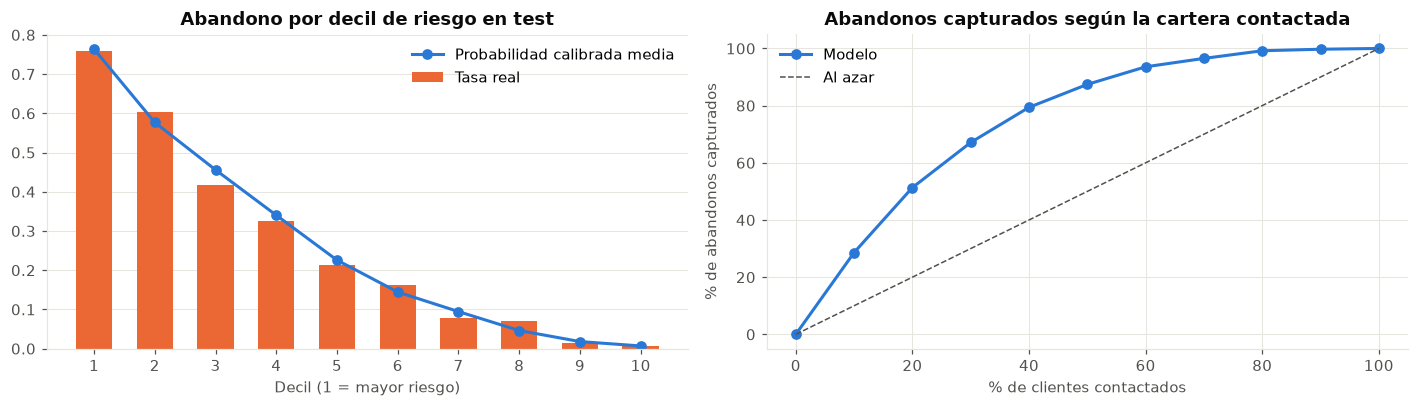

,clientes,abandonos,tasa_real,prob_media,captura_acumulada
decil,,,,,
1,141,107,0.7589,0.7636,0.2861
2,141,85,0.6028,0.5767,0.5134
3,141,59,0.4184,0.4558,0.6711
4,141,46,0.3262,0.3402,0.7941
5,141,30,0.2128,0.2257,0.8743
6,141,23,0.1631,0.1443,0.9358
7,141,11,0.0780,0.0945,0.9652
8,141,10,0.0709,0.0462,0.9920
9,141,2,0.0142,0.0180,0.9973


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(decile_table.index, decile_table["tasa_real"], color=ORANGE, width=0.6, label="Tasa real")
axes[0].plot(decile_table.index, decile_table["prob_media"], color=BLUE, marker="o", linewidth=2,
             label="Probabilidad calibrada media")
axes[0].set_title("Abandono por decil de riesgo en test")
axes[0].set_xlabel("Decil (1 = mayor riesgo)")
axes[0].set_xticks(decile_table.index)
axes[0].legend()
axes[0].grid(axis="x", visible=False)

axes[1].plot(np.r_[0, decile_table.index * 10], np.r_[0, decile_table["captura_acumulada"]] * 100,
             color=BLUE, marker="o", linewidth=2, label="Modelo")
axes[1].plot([0, 100], [0, 100], color=MUTED, linestyle="--", linewidth=1, label="Al azar")
axes[1].set_title("Abandonos capturados según la cartera contactada")
axes[1].set_xlabel("% de clientes contactados")
axes[1].set_ylabel("% de abandonos capturados")
axes[1].legend()
plt.tight_layout()
plt.show()
decile_table

### Interpretación

**Con el 10 % del esfuerzo se llega a más de la cuarta parte de los abandonos.** De los 141 clientes con mayor riesgo, 107 abandonan de verdad (75.9 %), frente al 26.5 % de una selección al azar: un lift de **2.86x**.

**El techo de esa captura es 37.7 %.** Con 141 contactos y 374 abandonos, ni un modelo perfecto pasaría de ahí. El 28.6 % logrado equivale a tres cuartas partes de ese máximo.

**Ampliar la cartera rinde mucho al principio:** contactar al 20 % captura 51.3 % de los abandonos, al 30 % captura 67.1 % y al 40 % captura 79.4 %. A partir de ahí el retorno cae, porque el decil 5 ya tiene una tasa real de solo 21 %.

**Las probabilidades calibradas son creíbles por grupo.** En el decil 1 se estimó 76.4 % y ocurrió 75.9 %; en el decil 2, 57.7 % y 60.3 %. Esto permite usarlas para estimar ingreso en riesgo.

**Lo que este ranking no dice.** Indica quién tiene más riesgo, no quién cambiará de opinión con una oferta. Hay clientes que se irían de todos modos y otros a los que un contacto podría incluso despertarles la idea de irse. Medir eso exige un piloto con grupo de control.

## 9. Explainable AI: SHAP y LIME
Ambas técnicas se aplican al modelo seleccionado, siempre para la clase **Churn = Yes**: un valor positivo empuja hacia el abandono y uno negativo hacia la permanencia.

Explican la salida directa del bosque, antes de calibrar. La calibración es monótona, así que no altera qué variables suben o bajan el riesgo.

### 9.1 SHAP: explicación global
`TreeExplainer` calcula valores de Shapley exactos para árboles. Trabaja sobre la matriz transformada, por lo que cada categoría One-Hot recibe su propia contribución. Para leerlas por variable original, se suman las columnas de cada variable.

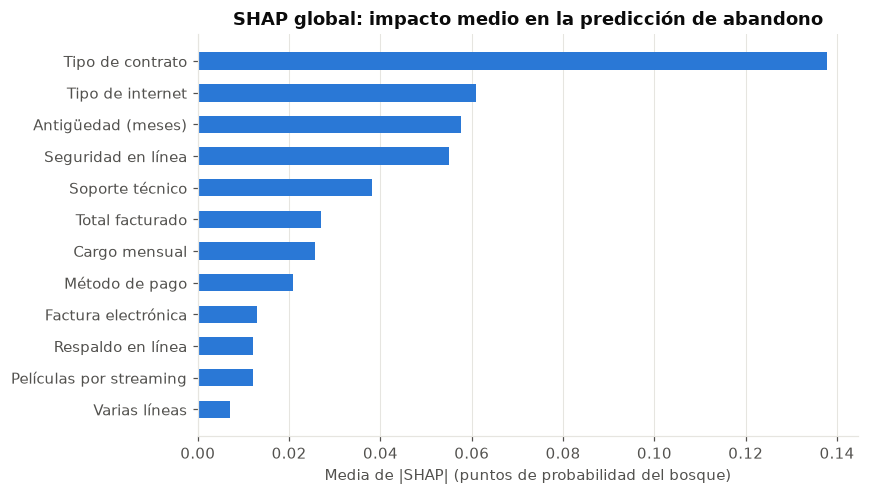

In [21]:
X_test_t = prep.transform(X_test)
tree_explainer = shap.TreeExplainer(rf_model)
shap_all = tree_explainer.shap_values(X_test_t)
assert shap_all.ndim == 3 and rf_model.classes_[1] == 1
shap_churn = shap_all[:, :, 1]                 # solo la clase de abandono
base_value = float(np.ravel(tree_explainer.expected_value)[1])

# Propiedad de SHAP: valor base + contribuciones = salida del modelo.
assert np.allclose(base_value + shap_churn.sum(axis=1), test_raw, atol=1e-6)

originals = [original_feature(n) for n in transformed_names]
shap_grouped = pd.DataFrame(shap_churn, columns=originals, index=X_test.index).T.groupby(level=0).sum().T
shap_global = shap_grouped.abs().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.6))
top_shap = shap_global.head(12)
ax.barh([LABELS[i] for i in top_shap.index], top_shap.values, color=BLUE, height=0.55)
ax.invert_yaxis()
ax.set_title("SHAP global: impacto medio en la predicción de abandono")
ax.set_xlabel("Media de |SHAP| (puntos de probabilidad del bosque)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

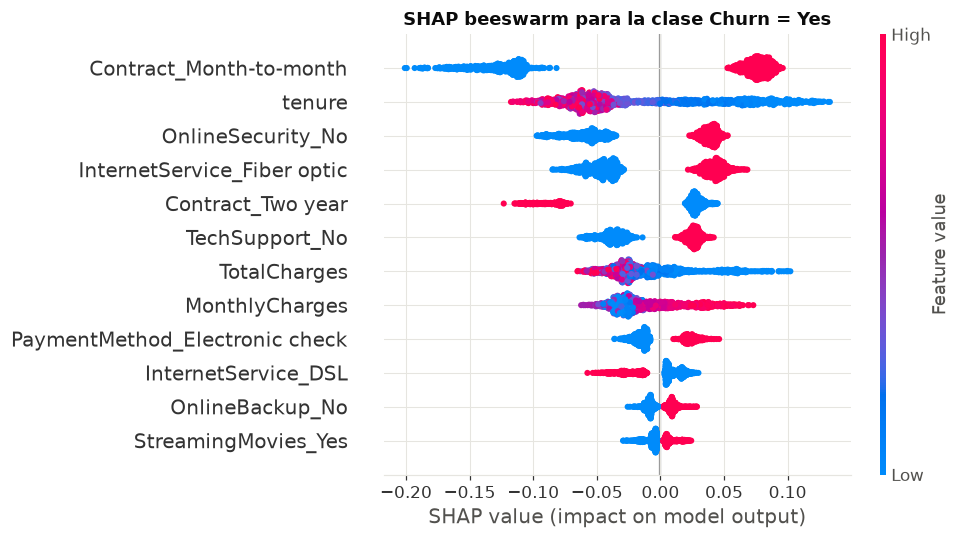

In [22]:
pretty = [n.split("__", 1)[1] for n in transformed_names]
shap.summary_plot(shap_churn, X_test_t, feature_names=pretty, max_display=12, show=False, plot_size=(9, 5))
plt.title("SHAP beeswarm para la clase Churn = Yes")
plt.tight_layout()
plt.show()

### Interpretación global

El orden por variable original es tipo de contrato, tipo de internet, antigüedad, seguridad en línea y soporte técnico. En el beeswarm cada punto es un cliente, el eje horizontal indica cuánto empuja hacia el abandono y el color indica el valor de la variable:

- **`Contract_Month-to-month`:** los valores altos (rojo, tener ese contrato) quedan a la derecha. Es el mayor empuje hacia el abandono.
- **`tenure`:** los valores bajos (azul) empujan hacia el abandono y los altos hacia la permanencia.
- **`Contract_Two year`:** tenerlo (rojo) reduce con fuerza el riesgo.
- **`OnlineSecurity_No`, `TechSupport_No` e `InternetService_Fiber optic`:** cuando el cliente está en esa situación, sube el riesgo.
- **`MonthlyCharges`:** cargos más altos tienden a subir el riesgo.
- **`TotalCharges`:** valores bajos suben el riesgo, en línea con la antigüedad, porque un total bajo suele ser un cliente nuevo.

El valor base es 0.50 y no 0.265 porque `class_weight="balanced"` iguala el peso de ambas clases durante el entrenamiento. Las contribuciones parten de ese punto y se expresan en la escala del bosque.

### 9.2 SHAP: dos predicciones individuales
Se eligen dos clientes típicos de test y no los extremos absolutos: el que está en el percentil 95 de riesgo y el que está en el percentil 5.

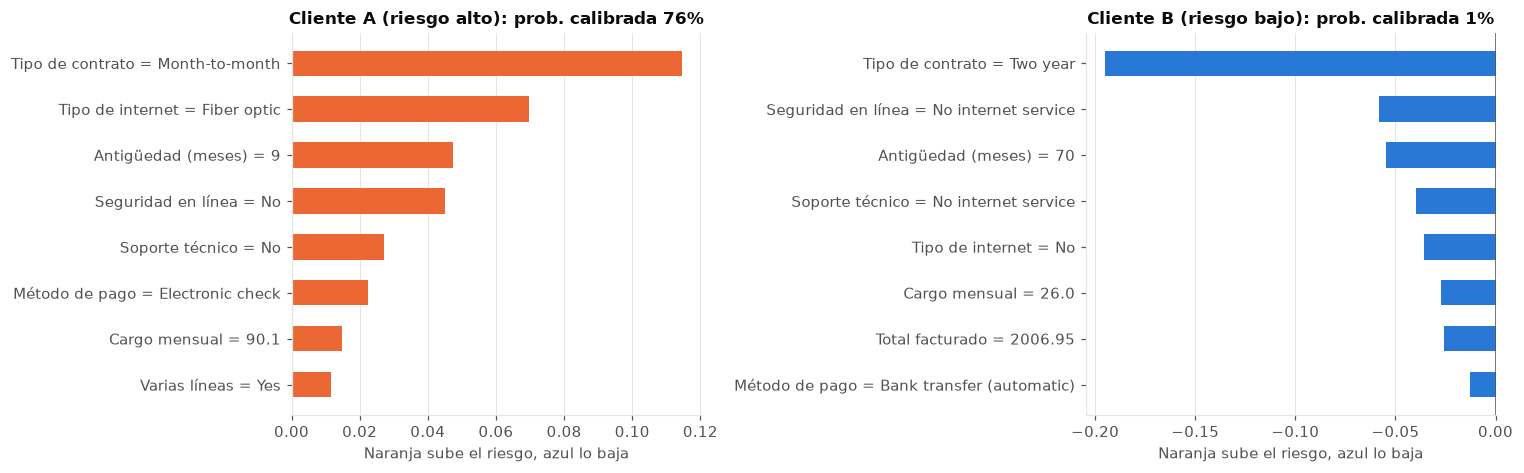

Valor base (salida media del bosque): 0.500


,caso,tenure,MonthlyCharges,Contract,InternetService,PaymentMethod,TechSupport,OnlineSecurity,p_calibrada,churn_real
6574,Cliente A (riesgo alto),9,90.1000,Month-to-month,Fiber optic,Electronic check,No,No,0.7626,0
4256,Cliente B (riesgo bajo),70,26.0000,Two year,No,Bank transfer (automatic),No internet service,No internet service,0.0071,0


In [23]:
def nearest_to_quantile(q):
    target = np.quantile(test_cal, q)
    return X_test.index[int(np.argmin(np.abs(test_cal - target)))]


cases = {"Cliente A (riesgo alto)": nearest_to_quantile(0.95),
         "Cliente B (riesgo bajo)": nearest_to_quantile(0.05)}


def contribution_plot(ax, series, title, xlabel):
    series = series.reindex(series.abs().sort_values(ascending=True).index)
    colors = [ORANGE if v > 0 else BLUE for v in series.values]
    ax.barh(series.index, series.values, color=colors, height=0.55)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
case_shap = {}
for ax, (name, idx) in zip(axes, cases.items()):
    row = shap_grouped.loc[idx]
    top_rows = row.reindex(row.abs().sort_values(ascending=False).index).head(8)
    labelled = pd.Series(top_rows.values, index=[f"{LABELS[f]} = {X_test.loc[idx, f]}" for f in top_rows.index])
    case_shap[name] = top_rows
    pos = X_test.index.get_loc(idx)
    contribution_plot(ax, labelled, f"{name}: prob. calibrada {test_cal[pos]:.0%}",
                      "Naranja sube el riesgo, azul lo baja")
plt.tight_layout()
plt.show()

summary = X_test.loc[list(cases.values()), ["tenure", "MonthlyCharges", "Contract", "InternetService",
                                            "PaymentMethod", "TechSupport", "OnlineSecurity"]].copy()
summary.insert(0, "caso", list(cases.keys()))
summary["p_calibrada"] = [test_cal[X_test.index.get_loc(i)] for i in cases.values()]
summary["churn_real"] = [y_test.loc[i] for i in cases.values()]
print(f"Valor base (salida media del bosque): {base_value:.3f}")
summary

### Interpretación individual

**Cliente A: probabilidad calibrada de 76 %.** Lleva 9 meses, paga $90.10, tiene contrato mes a mes, fibra óptica, cheque electrónico y no tiene seguridad ni soporte técnico. Los mayores aportes al riesgo son el contrato (+0.115), la fibra (+0.070), la antigüedad (+0.047) y la falta de seguridad (+0.045). Ningún factor destacado lo compensa.

**Este cliente en realidad no abandonó:** es un falso positivo. No es una anomalía, sino lo que significa una probabilidad de 76 %: en ese grupo de riesgo, alrededor de 1 de cada 4 clientes se queda. El caso muestra por qué una predicción individual no es una certeza.

**Cliente B: probabilidad calibrada de 0.7 %.** Lleva 70 meses, paga $26, tiene contrato de dos años, no tiene internet y paga por transferencia automática. Todos los factores principales reducen el riesgo, sobre todo el contrato (−0.195). Este cliente se quedó, como predijo el modelo.

**Lectura correcta del preprocesamiento.** `Seguridad en línea = No internet service` no significa que le falte seguridad, sino que no contrató internet. Por eso reduce su riesgo, mientras que `Seguridad en línea = No` en el Cliente A lo aumenta.

### 9.3 LIME: los mismos dos clientes
LIME genera clientes parecidos alrededor del caso, los puntúa con el modelo y ajusta una regresión lineal local que imita al bosque en esa zona.

Trabaja sobre las **variables originales**: las categorías se codifican como enteros solo para LIME, y su función de predicción las reconvierte antes de pasar por el pipeline completo. Se pide la etiqueta 1, es decir Churn = Yes.

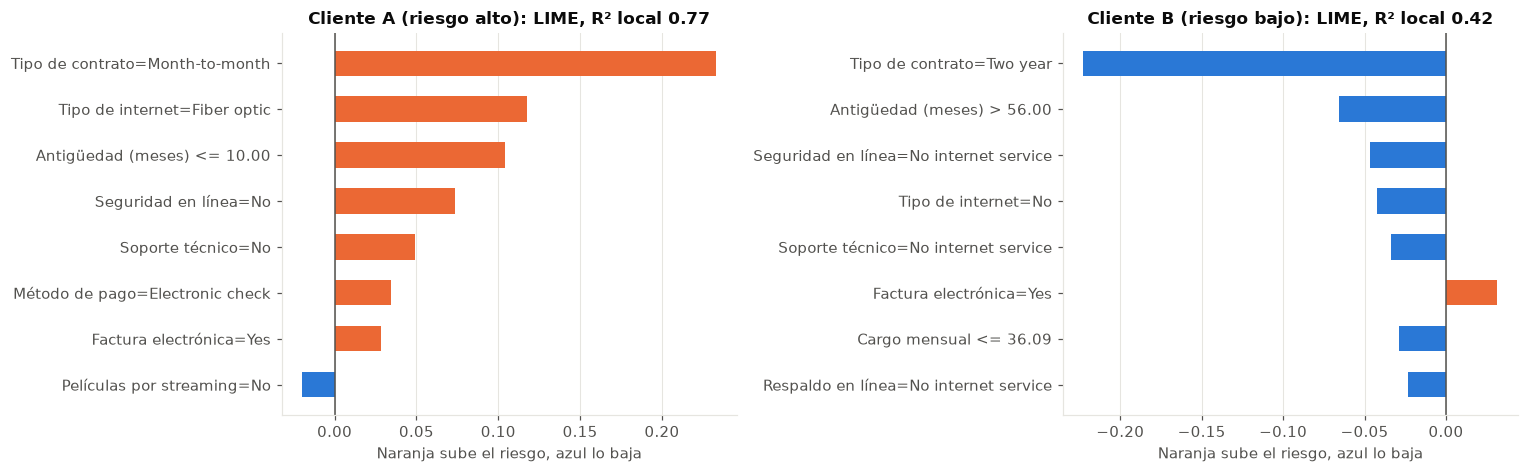

,top5_SHAP,top5_LIME,en_comun,mismo_signo
caso,,,,
Cliente A (riesgo alto),"[Tipo de contrato, Tipo de internet, Antigüedad (meses), Seguridad en línea, Soporte técnico]","[Tipo de contrato, Tipo de internet, Antigüedad (meses), Seguridad en línea, Soporte técnico]",5,5
Cliente B (riesgo bajo),"[Tipo de contrato, Seguridad en línea, Antigüedad (meses), Soporte técnico, Tipo de internet]","[Tipo de contrato, Antigüedad (meses), Seguridad en línea, Tipo de internet, Soporte técnico]",5,5


In [24]:
category_maps = lime_category_maps(X_train)
background = X_train.sample(1000, random_state=RANDOM_STATE)
background_encoded = lime_encode(background, category_maps)
cat_positions = [FEATURES.index(c) for c in CATEGORICAL]


def make_lime():
    return LimeTabularExplainer(
        background_encoded, mode="classification", feature_names=FEATURES,
        class_names=["No", "Yes"], categorical_features=cat_positions,
        categorical_names={FEATURES.index(c): category_maps[c] for c in CATEGORICAL},
        discretize_continuous=True, random_state=RANDOM_STATE)


def predict_for_lime(encoded):
    return final_pipe.predict_proba(lime_decode(encoded, category_maps))


lime_explainer = make_lime()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
case_lime = {}
for ax, (name, idx) in zip(axes, cases.items()):
    instance = lime_encode(X_test.loc[[idx]], category_maps)[0]
    exp = lime_explainer.explain_instance(instance, predict_for_lime, labels=(1,),
                                          num_features=8, num_samples=3000)
    weights = pd.Series({lime_label(rule): w for rule, w in exp.as_list(label=1)})
    case_lime[name] = {FEATURES[i]: w for i, w in exp.as_map()[1]}
    contribution_plot(ax, weights, f"{name}: LIME, R² local {exp.score:.2f}",
                      "Naranja sube el riesgo, azul lo baja")
plt.tight_layout()
plt.show()

overlap = []
for name in cases:
    shap_top = list(case_shap[name].index[:5])
    lime_top = sorted(case_lime[name], key=lambda f: -abs(case_lime[name][f]))[:5]
    same_sign = sum(np.sign(case_shap[name].get(f, 0)) == np.sign(case_lime[name][f])
                    for f in set(shap_top) & set(lime_top))
    overlap.append({"caso": name, "top5_SHAP": [LABELS[f] for f in shap_top],
                    "top5_LIME": [LABELS[f] for f in lime_top],
                    "en_comun": len(set(shap_top) & set(lime_top)), "mismo_signo": int(same_sign)})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(overlap).set_index("caso")

### 9.4 Comparación de técnicas
LIME es local, de modo que para compararlo a nivel global se promedia el peso absoluto en una muestra de 100 clientes de test.

In [25]:
def lime_global(n=100):
    explainer = make_lime()
    sample = X_test.sample(n, random_state=RANDOM_STATE)
    totals = pd.Series(0.0, index=FEATURES)
    for i in range(n):
        instance = lime_encode(sample.iloc[[i]], category_maps)[0]
        exp = explainer.explain_instance(instance, predict_for_lime, labels=(1,),
                                         num_features=len(FEATURES), num_samples=1500)
        for feature, weight in exp.as_map()[1]:
            totals[FEATURES[feature]] += abs(weight)
    return totals / n


lime_series = cached("lime_global", lime_global)

importance_table = pd.DataFrame({
    "RF Feature Importance": rf_grouped,
    "Permutation Importance": perm_series,
    "SHAP media |valor|": shap_global,
    "LIME media |peso|": lime_series,
})
ranks = importance_table.rank(ascending=False).astype(int)
ranks.columns = [f"rango {c.split()[0]}" for c in ranks.columns]
ranking_table = ranks.sort_values("rango SHAP")
ranking_table.index = [LABELS[i] for i in ranking_table.index]
print("Correlación de Spearman entre rankings:")
print(ranks.corr(method="spearman").round(2).to_string())
ranking_table

Correlación de Spearman entre rankings:
                   rango RF  rango Permutation  rango SHAP  rango LIME
rango RF             1.0000             0.8700      0.9600      0.9100
rango Permutation    0.8700             1.0000      0.9300      0.9500
rango SHAP           0.9600             0.9300      1.0000      0.9600
rango LIME           0.9100             0.9500      0.9600      1.0000


,rango RF,rango Permutation,rango SHAP,rango LIME
Tipo de contrato,1,1,1,1
Tipo de internet,4,3,2,2
Antigüedad (meses),2,2,3,3
Seguridad en línea,3,5,4,4
Soporte técnico,5,6,5,5
Total facturado,6,4,6,7
Cargo mensual,7,7,7,6
Método de pago,8,10,8,9
Factura electrónica,11,8,9,8
Respaldo en línea,9,13,10,12


### Análisis comparativo

**¿Qué similitudes y diferencias hay entre SHAP y LIME?**

*Similitudes.* En ambos clientes coinciden las 5 variables principales y todas con el mismo signo. A nivel global, sus rankings tienen una correlación de Spearman de 0.96, y ambos ordenan igual el Top 5.

*Diferencias.*

| Aspecto | SHAP | LIME |
|---|---|---|
| Método | Valores de Shapley, exactos en árboles | Regresión lineal local sobre clientes simulados |
| Propiedad | Base + contribuciones = salida del modelo (comprobado con `assert`) | No suma la predicción; es una aproximación |
| Estabilidad | Determinista | Depende de la semilla, la muestra y el tamaño del vecindario |
| Forma de la explicación | Aporte de cada valor | Reglas como `Antigüedad <= 10` |
| Variables | Sobre columnas transformadas, agrupadas después | Directamente sobre variables originales |

Las magnitudes no son comparables: para el contrato del Cliente A, LIME da cerca de +0.23 y SHAP +0.115. LIME también incluye en el Cliente B `Factura electrónica = Yes` con efecto positivo, que no aparece entre los principales de SHAP.

La calidad del ajuste de LIME varía: R² local de 0.77 en el Cliente A, pero solo 0.42 en el Cliente B. Esa segunda explicación debe tomarse con más reserva.

**¿Qué características resultaron relevantes?** Tipo de contrato es la primera en las cuatro medidas. Antigüedad, tipo de internet, seguridad en línea y soporte técnico aparecen en los primeros puestos de forma consistente. Género y tener pareja quedan al final, con poca aportación.

**¿Cómo se explica una predicción a alguien sin conocimientos técnicos?**

> "De cada 100 clientes parecidos a este, cerca de 76 se irían. El sistema se fija sobre todo en que no tiene un contrato de permanencia, lleva pocos meses con nosotros y no tiene contratados servicios de seguridad ni soporte. Esto no significa que se vaya a ir con seguridad, ni que esas sean las causas: es una señal para priorizar una llamada."

**¿Qué limitaciones tienen ambas técnicas?**
- Explican **el modelo, no la realidad**: si el modelo se equivoca, la explicación describe ese error de forma convincente. El Cliente A es un ejemplo.
- Ninguna demuestra causalidad.
- Con variables correlacionadas, como antigüedad y `TotalCharges`, el crédito se reparte de forma poco intuitiva.
- Explican la salida antes de calibrar, así que sus números no suman la probabilidad mostrada al usuario.
- LIME además es inestable y su vecindario puede crear clientes poco realistas, como combinaciones de servicios que no existen.

**Comparación con Feature Importance de Random Forest.** La tabla anterior muestra los rangos. Las cuatro medidas coinciden en lo esencial: la correlación con SHAP es de 0.96 para Feature Importance y 0.93 para permutación. Las más importantes según Random Forest son tipo de contrato, antigüedad, seguridad en línea, tipo de internet y soporte técnico.

Las diferencias son de orden: Random Forest coloca la antigüedad segunda y SHAP la coloca tercera, detrás del tipo de internet. Lo fundamental es qué pregunta responde cada una: Feature Importance es global y sin dirección, mientras que SHAP y LIME añaden el sentido y permiten explicar a un cliente concreto.

> La importancia predictiva no implica causalidad: estas técnicas muestran en qué se apoya el modelo, no qué provoca el abandono.

## 10. Propuesta de negocio
Respuestas a las preguntas de la práctica, basadas en los resultados anteriores. La propuesta comercial completa está en `docs/propuesta_negocio.md`.

In [26]:
rest = ranking.iloc[k:]
profile = pd.DataFrame({
    "Top 10 % de riesgo": [
        (top["Contract"] == "Month-to-month").mean(), (top["InternetService"] == "Fiber optic").mean(),
        (top["PaymentMethod"] == "Electronic check").mean(), (top["TechSupport"] == "No").mean(),
        (top["OnlineSecurity"] == "No").mean(), top["tenure"].median(), top["MonthlyCharges"].median()],
    "Resto de clientes": [
        (rest["Contract"] == "Month-to-month").mean(), (rest["InternetService"] == "Fiber optic").mean(),
        (rest["PaymentMethod"] == "Electronic check").mean(), (rest["TechSupport"] == "No").mean(),
        (rest["OnlineSecurity"] == "No").mean(), rest["tenure"].median(), rest["MonthlyCharges"].median()],
}, index=["Contrato mes a mes", "Fibra óptica", "Pago electrónico (cheque)", "Sin soporte técnico",
          "Sin seguridad en línea", "Antigüedad mediana (meses)", "Cargo mensual mediano"])
profile

,Top 10 % de riesgo,Resto de clientes
Contrato mes a mes,1.0000,0.4984
Fibra óptica,0.9716,0.3754
Pago electrónico (cheque),0.7447,0.2910
Sin soporte técnico,0.9574,0.4472
Sin seguridad en línea,0.9929,0.4424
Antigüedad mediana (meses),3.0000,33.0000
Cargo mensual mediano,79.5000,65.2250


### Respuestas basadas en los resultados

**1. ¿Qué perfiles presentan mayor riesgo?** Clientes nuevos con contrato mes a mes y fibra óptica, sin servicios de seguridad ni soporte. En el 10 % de mayor riesgo, todos tienen contrato mes a mes (frente a 49.8 % en el resto), 97.2 % tiene fibra (37.5 %), 74.5 % paga con cheque electrónico (29.1 %) y la antigüedad mediana es de 3 meses (33 en el resto).

**2. ¿Cuáles son las características más relevantes?** Tipo de contrato, antigüedad, tipo de internet, seguridad en línea y soporte técnico.

**3. Acciones de retención a evaluar.** Son hipótesis que deben probarse con grupo de control:
- **Migración a plan anual** con un beneficio, dirigida a clientes mes a mes de mayor valor.
- **Acompañamiento en los primeros 90 días:** llamada de bienvenida y revisión de la instalación, por la concentración del abandono al inicio.
- **Prueba gratuita de seguridad o soporte técnico** para clientes de fibra que no los tienen.
- **Incentivo para pasar a pago automático**, para quienes usan cheque electrónico.
- **Revisión de la experiencia de fibra:** comprobar si hay un problema de precio o de calidad detrás del 42 % de abandono.

**4. ¿Qué métrica se priorizaría?** Con presupuesto limitado, la **precisión y la captura dentro del porcentaje contactado**, que dependen de un buen orden (ROC-AUC). Aquí son 75.9 % y 28.6 % al 10 %. F1 sirve para comparar modelos, pero la decisión real es a quién contactar con lo que hay. Si no hubiera límite de presupuesto, se priorizaría el recall.

**5. ¿Qué costo tiene un falso negativo?** *Cálculo hipotético:* el cargo mediano del 10 % de mayor riesgo es de $79.50 al mes, unos $954 en 12 meses. Si una oferta costara $15, perder a un cliente valdría cerca de 64 veces más que contactar a alguien sin necesidad. Solo el cargo sale del dataset; el coste de la oferta y el horizonte son supuestos. Además, faltaría sumar lo que cuesta captar un cliente nuevo.

**6. Con presupuesto para el 10 %, ¿cómo se usa el ranking?** Se ordena por valor esperado, no solo por probabilidad: un cliente con riesgo algo menor y un cargo alto puede convenir más. Es lo que hace la sección de negocio de la app. Se contacta de arriba abajo hasta agotar el presupuesto, reservando una parte aleatoria como grupo de control.

**7. ¿Qué limitaciones existen al convertir importancia en acción?**
- La importancia muestra asociación, no causa.
- Algunas variables no se pueden accionar, como la antigüedad o ser adulto mayor.
- Riesgo alto no equivale a cliente persuadible.
- El dataset no incluye calidad del servicio, reclamos, competencia ni el motivo real de salida.
- Es una foto de una telco ficticia de EE. UU., por lo que hay que reentrenar con datos propios antes de usarlo en un ISP real.

## 11. Exportación de modelos y resultados
La aplicación de Streamlit solo carga estos archivos; no reentrena.

In [27]:
extra_models = {"logreg_pipeline": make_pipeline(logreg()), "catboost_pipeline": make_pipeline(catboost())}
for name, pipe in extra_models.items():
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, ARTIFACTS / f"{name}.joblib", compress=3)

joblib.dump(final_pipe, ARTIFACTS / "rf_final_pipeline.joblib", compress=3)
joblib.dump(calibrator, ARTIFACTS / "calibrator.joblib")
joblib.dump({"background": background_encoded, "category_maps": category_maps},
            ARTIFACTS / "lime_background.joblib", compress=3)

model_comparison.reset_index().to_csv(ARTIFACTS / "model_comparison.csv", index=False)
optimizers.reset_index().to_csv(ARTIFACTS / "optimizers.csv", index=False)
trials.to_csv(ARTIFACTS / "pareto_trials.csv", index=False)
pd.DataFrame({r["estrategia"]: pd.Series(np.maximum.accumulate(r["f1_por_ensayo"])) for r in results}).to_csv(
    ARTIFACTS / "best_so_far.csv", index=False)
decile_table.reset_index().to_csv(ARTIFACTS / "deciles.csv", index=False)
scored.to_csv(ARTIFACTS / "test_scored.csv", index=False)
importance_table.rename_axis("variable").reset_index().to_csv(ARTIFACTS / "importance_comparison.csv", index=False)

metadata = {
    "selected_params": selected_params,
    "threshold_raw": threshold_raw,
    "threshold_calibrated": threshold_cal,
    "cv_metrics": cv_final,
    "test_metrics": test_metrics,
    "test_confusion": test_confusion.tolist(),
    "oof_confusions": {k: v.tolist() for k, v in oof_confusions.items()},
    "knee": {"f1": float(knee["f1"]), "latencia_ms": float(knee["latencia_ms"]), "ensayo": int(knee["ensayo"])},
    "top_decile": {"k": k, "precision": float(precision_at_k), "capture": float(capture), "lift": float(lift)},
    "base_rate_test": float(y_test.mean()),
}
(ARTIFACTS / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

for path in sorted(ARTIFACTS.glob("*.joblib")):
    print(f"{path.name:32s} {path.stat().st_size / 1e6:6.2f} MB")

calibrator.joblib                  0.00 MB
catboost_pipeline.joblib           0.16 MB
lime_background.joblib             0.02 MB
logreg_pipeline.joblib             0.00 MB
rf_final_pipeline.joblib           0.43 MB


### Checklist

**Plantilla de clase**
- [x] Auditoría y preparación.
- [x] Pipeline sin leakage.
- [x] Al menos dos modelos comparados.
- [x] CV y optimización.
- [x] Test usado solo al final.
- [x] Top 5–10 características relevantes.
- [x] Ranking de clientes por probabilidad.
- [x] Propuesta de negocio respaldada por resultados.
- [x] Discusión de feature importance ≠ causalidad.

**Enunciado**
- [x] Grid Search, Random Search, TPE y NSGA-II con presupuesto común.
- [x] Formulación multiobjetivo, soluciones no dominadas y frente de Pareto.
- [x] SHAP y LIME sobre los mismos dos clientes, con comparación.
- [x] Modelos y pipelines exportados para Streamlit.

### Conclusiones

1. El modelo final, un Random Forest de 98 árboles, logra en test un F1 de 0.629, recall de 0.709 y ROC-AUC de 0.846, en línea con la validación cruzada.
2. Su mayor valor práctico es priorizar: en el 10 % de mayor riesgo, 75.9 % de los clientes abandona, 2.86 veces más que al azar.
3. Optimizar hiperparámetros aportó más que elegir entre optimizadores. TPE fue el más eficiente, pero sus diferencias con los demás no son concluyentes.
4. El Random Forest elegido no es el mejor en todo: CatBoost sin ajustar lo supera en F1 y latencia. Optimizar CatBoost es el siguiente paso natural.
5. SHAP y LIME coinciden en los factores principales, lo que da confianza en la explicación del modelo. No demuestran causas: eso requiere un piloto con grupo de control.